In [7]:
pip -q install langgraph langchain langchain-core langchain-groq groq

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [2]:
#2) Imports
#Groq SDK: streaming token a token.
#ChatGroq (LangChain): integração com LangGraph.
#LangGraph: grafos + checkpoints + interrupções.
#Também usamos:

#MemorySaver para checkpoints (necessário para breakpoints, interrupções e time travel);
#interrupt e Command para pausar e retomar.

from typing import TypedDict, Literal

from groq import Groq

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

In [3]:
def make_llm(temperature: float = 0.7) -> ChatGroq:
    return ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=temperature,
    )

llm = make_llm()
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000017EB53DEC90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000017EB5654E30>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
client = Groq()
completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {"role": "system", "content": "Responda em PT-BR, com clareza e didática"},
        {"role": "user", "content": "Explique o que é streaming em LLM e suas utilidades"},
        

            
    ],
    temperature=0.9,
    max_completion_tokens=400,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
)
for chunk in completion:
     print(chunk.choices[0].delta.content or "", end="", flush=True)
print()

**Streaming em LLMs – O que é e por que isso importa?**  

---

## 1. O conceito básico

**Streaming** (ou **transmissão**) em grandes modelos de linguagem (LLMs) é a capacidade de **enviar a saída do modelo token a token, à medida que ele vai gerando o texto**, em vez de esperar que toda a resposta esteja pronta antes de devolvê‑la ao cliente.

- **Sem streaming**: o cliente faz a requisição → o servidor roda o modelo → o modelo produz toda a sequência → o servidor devolve a resposta completa de uma só vez.  
- **Com streaming**: o cliente faz a requisição → o modelo começa a gerar o primeiro token → esse token é enviado imediatamente → o próximo token é gerado e enviado, e assim sucessivamente, até o final.

> **Analogia:** É como assistir a um vídeo enquanto ele ainda está sendo baixado (streaming) versus esperar o download completo para só então assistir.

---

## 2. Como o streaming funciona tecnicamente

1. **Geração incremental** – LLMs são modelos autoregressivos: para gerar a 

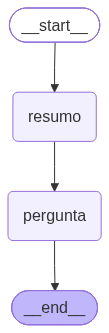

In [5]:
class StudyState(TypedDict, total=False):
    topic: str
    resumo: str
    pergunta: str

def node_resumo(state: StudyState) -> StudyState:
    topic = state.get("topic", "assunto não informado")
    resp = llm.invoke([
        SystemMessage(content="Você cria conteúdo didático em PT-BR."),
        HumanMessage(content=f"Faça um resumo bem curto (6-8 linhas) sobre: {topic}.")
    ])
    return {"resumo": resp.content}

def node_pergunta(state: StudyState) -> StudyState:
    resp = llm.invoke([
        SystemMessage(content="Você cria conteúdo didático em PT-BR."),
        HumanMessage(content=(
            "Crie 1 pergunta conceitual (com resposta curta) baseada no resumo abaixo:\n\n"
            f"{state.get('resumo','')}"
        ))
    ])
    return {"pergunta": resp.content}

builder = StateGraph(StudyState)
builder.add_node("resumo", node_resumo)
builder.add_node("pergunta", node_pergunta)
builder.add_edge(START, "resumo")
builder.add_edge("resumo", "pergunta")
builder.add_edge("pergunta", END)

study_graph = builder.compile()
study_graph


In [6]:
inputs = {"topic": "Breakpoints e depuração no LangGraph"}

for event in study_graph.stream(inputs, stream_mode="updates", ):
    print(event)

{'resumo': {'resumo': '**Breakpoints e depuração no LangGraph**\n\n- **Breakpoints** são marcadores que você insere nos nós ou nas transições do fluxo para interromper a execução e inspecionar o estado interno da aplicação.  \n- Eles podem ser definidos via interface visual ou programaticamente, permitindo pausar a execução antes ou depois de cada chamada de ferramenta, LLM ou função personalizada.  \n- Ao atingir um breakpoint, o console exibe as variáveis de contexto, mensagens trocadas e resultados parciais, facilitando a identificação de erros lógicos.  \n- O **modo de depuração** oferece “step‑over”, “step‑into” e “continue”, permitindo avançar nó a nó ou entrar nas sub‑rotinas chamadas.  \n- Logs detalhados e visualizações de grafos são atualizados em tempo real, ajudando a rastrear caminhos alternativos e ciclos.  \n- Use breakpoints temporários para testes rápidos e salve configurações persistentes para sessões de desenvolvimento recorrentes.'}}
{'pergunta': {'pergunta': '**Per

In [7]:
for event in study_graph.stream(inputs, stream_mode="values"):
    print(event)

{'topic': 'Breakpoints e depuração no LangGraph'}
{'topic': 'Breakpoints e depuração no LangGraph', 'resumo': '**Breakpoints e depuração no LangGraph**  \n\n- Breakpoints são marcadores que interrompem a execução do grafo em nós específicos, permitindo inspecionar o estado interno.  \n- Eles podem ser definidos tanto via interface visual quanto programaticamente usando `graph.set_breakpoint(node_id)`.  \n- Quando o fluxo para em um breakpoint, o console exibe variáveis de contexto, mensagens trocadas e valores de saída dos nós.  \n- É possível avançar passo a passo (step‑over) ou retomar a execução completa (continue) a partir do ponto de parada.  \n- O depurador também oferece “watchers” para monitorar alterações em variáveis ou parâmetros ao longo do fluxo.  \n- Utilizar breakpoints facilita a identificação de erros lógicos, loops infinitos e problemas de integração entre componentes do LangGraph.'}
{'topic': 'Breakpoints e depuração no LangGraph', 'resumo': '**Breakpoints e depuraçã

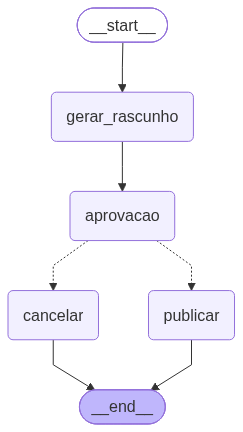

In [8]:
class PublishState(TypedDict, total=False):
    tema: str
    rascunho: str
    aprovado: bool
    publicado: str

def node_gerar_rascunho(state: PublishState) -> PublishState:
    tema = state.get("tema", "tema não informado")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, tom neutro e didático."),
        HumanMessage(content=(
            f"Crie um rascunho curto (máx 12 linhas) de uma prática usada em sobre: {tema}.\n"
            "Inclua: definição, exemplo e um alerta de erro comum."
        ))
    ])
    return {"rascunho": resp.content}

def node_aprovacao(state: PublishState) -> Command[Literal["publicar", "cancelar"]]:
    payload = {
        "pergunta": "Você aprova o rascunho para publicação?",
        "rascunho": state.get("rascunho", "")
    }
    decisao = interrupt(payload)  # PAUSA AQUI

    if decisao is True:
        return Command(goto="publicar", update={"aprovado": True})
    return Command(goto="cancelar", update={"aprovado": False})

def node_publicar(state: PublishState) -> PublishState:
    texto = state.get("rascunho", "")
    return {"publicado": "✅ PUBLICADO (simulação)\n\n" + texto}

def node_cancelar(state: PublishState) -> PublishState:
    return {"publicado": "❌ Cancelado: o rascunho não foi aprovado."}

pub_builder = StateGraph(PublishState)
pub_builder.add_node("gerar_rascunho", node_gerar_rascunho)
pub_builder.add_node("aprovacao", node_aprovacao)
pub_builder.add_node("publicar", node_publicar)
pub_builder.add_node("cancelar", node_cancelar)

pub_builder.add_edge(START, "gerar_rascunho")
pub_builder.add_edge("gerar_rascunho", "aprovacao")
pub_builder.add_edge("publicar", END)
pub_builder.add_edge("cancelar", END)

pub_checkpointer = MemorySaver()
pub_graph = pub_builder.compile(checkpointer=pub_checkpointer)
pub_graph

In [9]:
config = {"configurable": {"thread_id": "pub-01"}}

result = pub_graph.invoke({"tema": "Príncipios básicos da computação quântica"}, config=config)
print("Interrupção recebida:")
print(result.get("__interrupt__"))

Interrupção recebida:
[Interrupt(value={'pergunta': 'Você aprova o rascunho para publicação?', 'rascunho': "**Rascunho de prática – Princípios básicos da computação quântica**\n\n1. **Definição** – Qubit: unidade de informação quântica que, ao contrário do bit clássico (0 ou 1), pode estar em superposição de ambos os estados simultaneamente.  \n2. **Superposição** – Representada por \\|ψ⟩ = α\\|0⟩ + β\\|1⟩, onde |α|² + |β|² = 1.  \n3. **Exemplo prático** – Use o simulador Qiskit\u202fLite para criar um circuito com um único qubit, aplicar a porta Hadamard (H) e medir. O resultado deve ser “0” ou “1” com aproximadamente 50\u202f% de probabilidade cada.  \n4. **Passo a passo**:  \n   a) Crie o circuito `qc = QuantumCircuit(1,1)`;  \n   b) Adicione `qc.h(0)`;  \n   c) Meça com `qc.measure(0,0)`.  \n5. **Execução** – Rode o circuito em um backend de simulador (por exemplo, `Aer.get_backend('qasm_simulator')`) com 1024 disparos.  \n6. **Análise** – Verifique a distribuição de resultados; a 

In [10]:
#APROVACAO HUMANA
final = pub_graph.invoke(Command(resume=True), config=config)
print(final["publicado"])

✅ PUBLICADO (simulação)

**Rascunho de prática – Princípios básicos da computação quântica**

1. **Definição** – Qubit: unidade de informação quântica que, ao contrário do bit clássico (0 ou 1), pode estar em superposição de ambos os estados simultaneamente.  
2. **Superposição** – Representada por \|ψ⟩ = α\|0⟩ + β\|1⟩, onde |α|² + |β|² = 1.  
3. **Exemplo prático** – Use o simulador Qiskit Lite para criar um circuito com um único qubit, aplicar a porta Hadamard (H) e medir. O resultado deve ser “0” ou “1” com aproximadamente 50 % de probabilidade cada.  
4. **Passo a passo**:  
   a) Crie o circuito `qc = QuantumCircuit(1,1)`;  
   b) Adicione `qc.h(0)`;  
   c) Meça com `qc.measure(0,0)`.  
5. **Execução** – Rode o circuito em um backend de simulador (por exemplo, `Aer.get_backend('qasm_simulator')`) com 1024 disparos.  
6. **Análise** – Verifique a distribuição de resultados; a soma das contagens deve aproximar 512 para cada saída.  
7. **Alerta de erro comum** – Esquecer de normali

In [11]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quando usar ferramentas em agentes"}, config=config2)
final2 = pub_graph.invoke(Command(resume=False), config=config2)
print(final2["publicado"])

❌ Cancelado: o rascunho não foi aprovado.


In [12]:
# 2. Definição do Estado
class PublishState(TypedDict, total=False):
  tema: str
  rascunho: str
  aprovado: bool
  publicado: str


# 3. Nós
def node_gerar_rascunho(state: PublishState) -> PublishState:
  tema = state.get("tema", "tema não informado")
  resp = llm.invoke([
      SystemMessage(content="Escreva em PT-BR, tom neutro e didático e prático, se possível."),
      HumanMessage(
          content=(
              f"Crie um rascunho curto (máx 12 linhas) sobre Computação Quântica"
              f" sobre: {tema}.\nInclua: definição, exemplo e um alerta de erro"
              " comum."
          )
      ),
  ])
  return {"rascunho": resp.content}


def node_aprovacao(state: PublishState) -> Command[Literal["publicar", "cancelar"]]:
  payload = {
      "pergunta": "Você aprova o rascunho para publicação?",
      "rascunho": state.get("rascunho", ""),
  }
  decisao = interrupt(payload)  # PAUSA AQUI

  if decisao is True:
    return Command(goto="publicar", update={"aprovado": True})
  return Command(goto="cancelar", update={"aprovado": False})


def node_publicar(state: PublishState) -> PublishState:
  texto = state.get("rascunho", "")
  return {"publicado": "✅ PUBLICADO (simulação)\n\n" + texto}


def node_cancelar(state: PublishState) -> PublishState:
  return {"publicado": "❌ Cancelado: o rascunho não foi aprovado."}


# 4. Construção e Compilação correta do Grafo
pub_builder = StateGraph(PublishState)
pub_builder.add_node("gerar_rascunho", node_gerar_rascunho)
pub_builder.add_node("aprovacao", node_aprovacao)
pub_builder.add_node("publicar", node_publicar)
pub_builder.add_node("cancelar", node_cancelar)

pub_builder.add_edge(START, "gerar_rascunho")
pub_builder.add_edge("gerar_rascunho", "aprovacao")
pub_builder.add_edge("publicar", END)
pub_builder.add_edge("cancelar", END)

pub_checkpointer = MemorySaver()
pub_graph = pub_builder.compile(checkpointer=pub_checkpointer)

# ==========================================
# COMO EXECUTAR (Lidando com o Interrupt)
# ==========================================
config = {"configurable": {"thread_id": "1"}}

# 1ª Execução: Vai gerar o rascunho e pausar na aprovação
print("--- Iniciando o Grafo ---")
events = pub_graph.stream(
    {"tema": "Computação Quântica"}, config
)
for event in events:
  print(event)

# 2ª Retomada: Enviando a decisão humana (True para aprovar, False para cancelar)
print("\n--- Retomando após a aprovação humana ---")
for event in pub_graph.stream(Command(resume=True), config):
  print(event)

--- Iniciando o Grafo ---
{'gerar_rascunho': {'rascunho': '**Computação Quântica – Rascunho Breve**\n\n1. **Definição:**  \n   Computação quântica é o uso de qubits, que podem estar em superposição de estados, para processar informações de forma exponencialmente mais eficiente que bits clássicos.\n\n2. **Princípio básico:**  \n   - *Superposição*: um qubit pode representar 0 e 1 simultaneamente.  \n   - *Emaranhamento*: qubits ligados compartilham estados, permitindo correlações instantâneas.\n\n3. **Exemplo prático:**  \n   Algoritmo de Shor (1994) fatoriza números inteiros grandes em tempo polinomial, ameaçando a criptografia RSA usada hoje.\n\n4. **Aplicação atual:**  \n   Simulação de moléculas para descoberta de fármacos, otimização de rotas logísticas e aprendizado de máquina quântico.\n\n5. **Alerta de erro comum:**  \n   **Confundir “qubit” com “bit clássico”.**  \n   Um qubit não armazena apenas 0 ou 1; ele mantém probabilidades que colapsam ao ser medido. Ignorar a necessidad

In [13]:
config = {"configurable": {"thread_id": "pub-01"}}

result = pub_graph.invoke({"tema": "Princípios da Computação Quântica"}, config=config)
print("Interrupção recebida:")
print(result.get("__interrupt__"))

Interrupção recebida:
[Interrupt(value={'pergunta': 'Você aprova o rascunho para publicação?', 'rascunho': '**Princípios da Computação Quântica – Rascunho**\n\n1. **Definição:** A computação quântica utiliza qubits, que podem estar em superposição de 0 e 1 simultaneamente, permitindo processar um número exponencial de estados em paralelo.  \n2. **Superposição:** Cada qubit representa uma combinação linear de |0⟩ e |1⟩, ampliando o espaço de busca de um algoritmo.  \n3. **Emaranhamento:** Qubits entrelaçados exibem correlações instantâneas; medir um afeta o estado do outro, mesmo à distância.  \n4. **Interferência:** Algoritmos quânticos reforçam amplitudes corretas e cancelam as errôneas, guiando a solução desejada.  \n5. **Exemplo prático:** O algoritmo de Shor fatoriza números grandes (ex.: 15 → 3\u202f×\u202f5) em tempo polinomial, algo inviável para computadores clássicos.  \n6. **Portas lógicas quânticas:** Operações unitárias como Hadamard (H), CNOT e fase (S) manipulam superposi

In [14]:
#B3) Retomando com rejeição (resume=False)


In [15]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quando usar ferramentas em agentes"}, config=config2)
final2 = pub_graph.invoke(Command(resume=False), config=config2)
print(final2["publicado"])

❌ Cancelado: o rascunho não foi aprovado.


In [16]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quais seus principais usos da Computação Quântica"}, config=config2)
final2 = pub_graph.invoke(Command(resume=True), config=config2)
print(final2["publicado"])

✅ PUBLICADO (simulação)

**Computação Quântica – Visão geral rápida**

1. **Definição:**  
   É o estudo e a aplicação de algoritmos que utilizam qubits – unidades de informação que podem estar simultaneamente em múltiplos estados (superposição) e se correlacionar por emaranhamento.

2. **Principais usos atuais:**  
   - **Criptografia:** Quebra de chaves RSA e geração de criptografia pós‑quântica.  
   - **Simulação de materiais:** Modelagem de moléculas complexas para fármacos e energia limpa.  
   - **Otimização:** Resolução de problemas logísticos (rotas, alocação de recursos) com algoritmos como QAOA.  
   - **Aprendizado de máquina:** Aceleração de treinamento de redes neurais via algoritmos quânticos.

3. **Exemplo prático:**  
   O algoritmo de Shor, rodado em um processador de 50 qubits, pode fatorar o número 15 em segundos, algo inviável para computadores clássicos.

4. **Alerta de erro comum:**  
   **Confundir superposição com paralelismo clássico.**  
   Muitos acreditam q

In [17]:
#PARTE C: Breakpoints (estaticos)

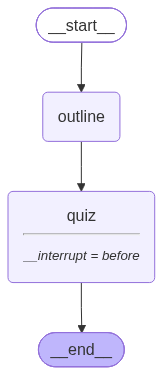

In [18]:
class DebugState(TypedDict, total=False):
    assunto: str
    outline: str
    quiz: str

def node_outline(state: DebugState) -> DebugState:
    assunto = state.get("assunto", "assunto")
    resp = llm.invoke([
        SystemMessage(content="Crie conteúdo em PT-BR, objetivo."),
        HumanMessage(content=f"Crie um outline com 4 tópicos sobre: {assunto}.")
    ])
    return {"outline": resp.content}

def node_quiz(state: DebugState) -> DebugState:
    resp = llm.invoke([
        SystemMessage(content="Crie conteúdo em PT-BR, objetivo."),
        HumanMessage(content=(
            "Crie 2 perguntas de múltipla escolha baseadas no outline abaixo:\n\n"
            f"{state.get('outline','')}\n\n"
            "Não precisa gabarito."
        ))
    ])
    return {"quiz": resp.content}

dbg_builder = StateGraph(DebugState)
dbg_builder.add_node("outline", node_outline)
dbg_builder.add_node("quiz", node_quiz)
dbg_builder.add_edge(START, "outline")
dbg_builder.add_edge("outline", "quiz")
dbg_builder.add_edge("quiz", END)

dbg_checkpointer = MemorySaver()
dbg_graph = dbg_builder.compile(checkpointer=dbg_checkpointer, interrupt_before=["quiz"])
dbg_graph

In [19]:
dbg_config = {"configurable": {"thread_id": "dbg-01"}}

partial = dbg_graph.invoke({"assunto": "Computação Quântica"}, config=dbg_config)
print("Parou no breakpoint. Estado parcial:")
print(partial)

print("\nContinuando...")
complete = dbg_graph.invoke(None, config=dbg_config)
print("\nEstado final:")
print(complete)

Parou no breakpoint. Estado parcial:
{'assunto': 'Computação Quântica', 'outline': '**Outline – Computação Quântica**\n\n1. **Fundamentos da mecânica quântica aplicados à computação**  \n   - Qubits: superposição e entrelaçamento  \n   - Portas lógicas quânticas (Hadamard, CNOT, fase)  \n   - Medição e colapso de estado\n\n2. **Arquiteturas e tecnologias de hardware quântico**  \n   - Supercondutores, íons aprisionados, fotônica e qubits topológicos  \n   - Cryogenia e controle de erro (códigos de correção quântica)  \n   - Escalabilidade e desafios de integração\n\n3. **Algoritmos quânticos e vantagens computacionais**  \n   - Algoritmo de Shor (fatoração) e implicações criptográficas  \n   - Algoritmo de Grover (busca não estruturada)  \n   - Simulação de sistemas quânticos e otimização combinatória\n\n4. **Aplicações práticas e perspectivas futuras**  \n   - Criptografia pós-quântica e segurança da informação  \n   - Descoberta de materiais e fármacos via simulação quântica  \n   - 

In [20]:
#Parte D — Breakpoints dinâmicos

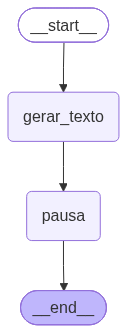

In [21]:
class DynBPState(TypedDict, total=False):
    tema: str
    texto: str
    modo_debug: bool

def node_gerar_texto(state: DynBPState) -> DynBPState:
    tema = state.get("tema", "tema")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR."),
        HumanMessage(content=f"Escreva uma explicação em até 10 linhas sobre: {tema}.")
    ])
    return {"texto": resp.content}

def node_pausa_condicional(state: DynBPState) -> DynBPState:
    if state.get("modo_debug"):
        interrupt({
            "motivo": "modo_debug ligado",
            "amostra_texto": state.get("texto", "")[:250]
        })
        return {}

    # Heurística extra: se ficar muito grande, também pausa
    if len(state.get("texto", "")) > 900:
        interrupt({"motivo": "texto longo demais", "tamanho": len(state.get("texto",""))})
    return {}

dyn_builder = StateGraph(DynBPState)
dyn_builder.add_node("gerar_texto", node_gerar_texto)
dyn_builder.add_node("pausa", node_pausa_condicional)
dyn_builder.add_edge(START, "gerar_texto")
dyn_builder.add_edge("gerar_texto", "pausa")
dyn_builder.add_edge("pausa", END)

dyn_checkpointer = MemorySaver()
dyn_graph = dyn_builder.compile(checkpointer=dyn_checkpointer)
dyn_graph

In [22]:
#D1) Sem pausa (modo_debug=False)
cfg = {"configurable": {"thread_id": "dyn-01"}}
res = dyn_graph.invoke({"tema": "Quais são as próximas evoluções da computação quântica?", "modo_debug": False}, config=cfg)
print("OK. Não pausou.\n")
print(res["texto"][:500], "...")

OK. Não pausou.

**Próximas evoluções da computação quântica**

1. **Qubits mais estáveis** – desenvolvimento de materiais e técnicas de controle que reduzem a decoerência, permitindo tempos de coerência mais longos.  
2. **Escalonamento de hardware** – chips com milhares de qubits físicos, usando arquiteturas modulares e interconexões ópticas para criar “quantum internet”.  
3. **Correção de erros quânticos** – implementação prática de códigos de correção (ex.: surface code) que permitam computação tolerante a  ...


In [23]:
#D2) Com pausa (modo_debug=True) e retomada
cfg2 = {"configurable": {"thread_id": "dyn-02"}}
res2 = dyn_graph.invoke({"tema": "Ciência básica da computação quântica", "modo_debug": True}, config=cfg2)

print("Pausou? Payload:")
print(res2.get("__interrupt__"))

print("\nRetomando...")
res2b = dyn_graph.invoke(Command(resume="seguir"), config=cfg2)
print("Concluiu. Texto (amostra):")
print(res2b["texto"][:350], "...")

Pausou? Payload:
[Interrupt(value={'motivo': 'modo_debug ligado', 'amostra_texto': 'A computação quântica estuda como usar propriedades da mecânica quântica\u202f—\u202fcomo superposição, emaranhamento e interferência\u202f—\u202fpara processar informações de forma diferente dos computadores clássicos.  \nUm **qubit** pode representar simultaneamente 0 '}, id='2fb6a75b9a4ade89af7d918022841eb5', response_schema=None)]

Retomando...
Concluiu. Texto (amostra):
A computação quântica estuda como usar propriedades da mecânica quântica — como superposição, emaranhamento e interferência — para processar informações de forma diferente dos computadores clássicos.  
Um **qubit** pode representar simultaneamente 0 e 1 (superposição), permitindo que um algoritmo explore muitas possibilidades ao mesmo tempo.  
Quan ...


In [24]:
#Parte E — Editando o estado (feedback humano)

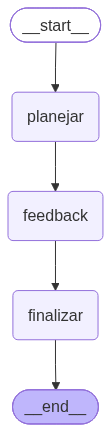

In [25]:
class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_planejar(state: FeedbackState) -> FeedbackState:
    tema = state.get("tema", "tema")
    nivel = state.get("nivel", "iniciante")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem prático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos para idéias de criações de Startups {tema}. "
            f"Nível: {nivel}. Inclua 1 exemplo prático."
        ))
    ])
    return {"roteiro": resp.content}

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    ajuste = interrupt({
        "pergunta": "Deseja ajustar o nível? (iniciante/intermediário/avançado) ou deixe em branco para manter.",
        "nivel_atual": state.get("nivel", "iniciante")
    })
    if isinstance(ajuste, str) and ajuste.strip():
        return {"nivel": ajuste.strip()}
    return {}

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro abaixo em uma versão final formatada:\n\n"
            f"TEMA: {state.get('tema')}\n"
            f"NÍVEL: {state.get('nivel')}\n\n"
            f"ROTEIRO:\n{state.get('roteiro','')}\n\n"
            "Inclua uma seção final: 'Erros comuns' com 3 itens."
        ))
    ])
    return {"versao_final": resp.content}

fb_builder = StateGraph(FeedbackState)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "planejar")
fb_builder.add_edge("planejar", "feedback")
fb_builder.add_edge("feedback", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [26]:
#E1) Rodar até o feedback (interrupt)

In [27]:
fb_config = {"configurable": {"thread_id": "fb-01"}}

part = fb_graph.invoke({"tema": "Ideias de Startups", "nivel": "iniciante"}, config=fb_config)
print("Payload do interrupt:")
print(part.get("__interrupt__"))

Payload do interrupt:
[Interrupt(value={'pergunta': 'Deseja ajustar o nível? (iniciante/intermediário/avançado) ou deixe em branco para manter.', 'nivel_atual': 'iniciante'}, id='2c3ea7ad34173a235c6c4da4951a2cec', response_schema=None)]


In [28]:
#E2) Retomar via resume (ex.: mudar para intermediário)

In [29]:
final_fb = fb_graph.invoke(Command(resume="avançado"), config=fb_config)
print("Nível final:", final_fb.get("nivel"))
print(final_fb["versao_final"][:700], "...")

Nível final: avançado
# **APOSTILA – IDEIAS DE STARTUPS**  
**Nível:** Avançado | **Formato:** 5 tópicos essenciais para transformar um problema real em um negócio escalável  

---

## Sumário  

1. [Identificando um Problema Real (e Simples)](#1)  
2. [Validando a Ideia com o Público‑Alvo](#2)  
3. [Definindo a Solução Minimalista – MVP](#3)  
4. [Estruturando o Modelo de Receita](#4)  
5. [Planejando os Próximos Passos e Métricas‑Chave](#5)  
6. [Exemplo Prático: FitMeal Delivery](#exemplo)  
7. [Dica Final para Iniciantes](#dica)  
8. [Erros Comuns (e como evitá‑los)](#erros)  

---

<a id="1"></a>  
## 1️⃣ Identifique um Problema Real (e Simples)

| O que fazer | Como fazer | Ferramentas úteis |
|------------ ...


In [30]:
#E3) Editar o estado via update_state e continuar

In [31]:
fb_config2 = {"configurable": {"thread_id": "fb-02"}}

# 1) para no feedback
fb_graph.invoke({"tema": "Breakpoints dinâmicos", "nivel": "iniciante"}, config=fb_config2)

# 2) mostra o estado atual
state_now = fb_graph.get_state(fb_config2)
print("Estado antes da edição:")
print(state_now.values)

# 3) atualiza o estado (correção humana)
new_cfg = fb_graph.update_state(
    fb_config2,
    values={"nivel": "avançado", "tema": "Breakpoints dinâmicos (com casos reais)"}
)

print("\nConfig retornado por update_state:", new_cfg)

# 4) continua a execução
cfg_to_use = new_cfg if new_cfg is not None else fb_config2
done = fb_graph.invoke(None, config=cfg_to_use)

print("\nEstado final (amostra):")
print("tema:", done.get("tema"))
print("nivel:", done.get("nivel"))
print(done.get("versao_final", "")[:700], "...")

Estado antes da edição:
{'tema': 'Breakpoints dinâmicos', 'nivel': 'iniciante', 'roteiro': '**Roteiro em 5 tópicos – Ideias de Startups com Breakpoints Dinâmicos (Nível Iniciante)**  \n\n---\n\n### 1️⃣ Identifique um problema real e mensurável  \n- **O que fazer:** Observe seu dia‑a‑dia, converse com amigos, participe de grupos online ou fóruns. Anote dores que geram custos (tempo, dinheiro, frustração) e que ainda não têm solução simples.  \n- **Como validar:** Crie uma enquete rápida (Google Forms, Instagram Stories) e verifique se\u202f≥\u202f30\u202f% das pessoas concordam que o problema é relevante.  \n\n---\n\n### 2️⃣ Defina o *breakpoint* inicial – o ponto onde o cliente decide pagar  \n- **Conceito:** O breakpoint é o momento em que o usuário vê valor suficiente para desembolsar dinheiro.  \n- **Exemplo de breakpoint simples:** “Economizar\u202f≥\u202fR$\u202f200\u202fpor mês” ou “Reduzir o tempo de execução de uma tarefa de 30\u202fmin para 5\u202fmin”.  \n- **Ação:** Estime, 

In [32]:
#Parte F — Time travel (viagem no tempo)
#listar checkpoints;
#voltar a um checkpoint antigo;
#alterar o estado naquele ponto;
#e continuar gerando um novo futuro (fork).

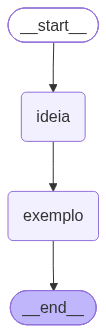

In [33]:
class TravelState(TypedDict, total=False):
    ideia: str
    exemplo: str

def node_ideia(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content="Gere uma ideia de uso (1 frase) para usar LangGraph em uma Startup de IA.")
    ])
    return {"ideia": resp.content.strip()}

def node_exemplo(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content=(
            "Crie um exemplo prático modelo de Startups de IA, de acordo com a ideia abaixo.\n"
            f"IDEIA: {state.get('ideia','')}\n"
            "Formato: 6-10 linhas, com bullets."
        ))
    ])
    return {"exemplo": resp.content}

travel_builder = StateGraph(TravelState)
travel_builder.add_node("ideia", node_ideia)
travel_builder.add_node("exemplo", node_exemplo)
travel_builder.add_edge(START, "ideia")
travel_builder.add_edge("ideia", "exemplo")
travel_builder.add_edge("exemplo", END)

travel_checkpointer = MemorySaver()
travel_graph = travel_builder.compile(checkpointer=travel_checkpointer)
travel_graph

In [34]:
#F1) Execução normal

In [35]:
t_cfg = {"configurable": {"thread_id": "travel-01"}}

original = travel_graph.invoke({}, config=t_cfg)
print("IDEIA ORIGINAL:", original.get("ideia"))
print("\nEXEMPLO ORIGINAL:\n", original.get("exemplo"))

IDEIA ORIGINAL: Use o LangGraph para coordenar fluxos de diálogos multi‑agente que combinam geração de texto, análise de dados e tomada de decisões em tempo real, permitindo que seu assistente de IA ofereça respostas contextuais e personalizadas em diferentes etapas do atendimento ao cliente.

EXEMPLO ORIGINAL:
 - **Nome da startup:** DialogFlow AI  
- **Problema:** Atendimento ao cliente fragmentado, com respostas genéricas e demora na resolução.  
- **Solução:** Plataforma que usa **LangGraph** para orquestrar agentes especializados (geração de texto, análise de dados, decisão em tempo real).  
- **Fluxo típico:**  
  1️⃣ Cliente abre chat → agente de **recepção** coleta contexto.  
  2️⃣ Dados são enviados ao agente de **análise** (consulta ao CRM, histórico de compras).  
  3️⃣ Agente de **decisão** define a ação (sugestão de produto, abertura de ticket, upsell).  
  4️⃣ Agente de **geração** cria resposta personalizada e envia ao cliente.  
- **Tecnologia:** LangGraph + LLMs (GPT‑

In [36]:
history = list(travel_graph.get_state_history(t_cfg))
print("Quantidade de checkpoints:", len(history))

for i, st in enumerate(history[:6]):
    checkpoint_id = st.config["configurable"].get("checkpoint_id")
    print(f"{i}: next={st.next} | checkpoint_id={checkpoint_id} | keys={list(st.values.keys())}")

Quantidade de checkpoints: 4
0: next=() | checkpoint_id=1f1d7e07-0b70-602c-8002-de60eb7d66d6 | keys=['ideia', 'exemplo']
1: next=('exemplo',) | checkpoint_id=1f1d7e07-0136-6433-8001-25e82fa40520 | keys=['ideia']
2: next=('ideia',) | checkpoint_id=1f1d7e06-fa84-6ac9-8000-e39feba42f48 | keys=[]
3: next=('__start__',) | checkpoint_id=1f1d7e06-fa80-6080-bfff-6eaec2013030 | keys=[]


In [37]:
#F3) Fork: alterando o passado e criando novo futuro
#Dica: normalmente history[1] é um ponto anterior ao último nó (dependendo da versão).

In [38]:
selected = history[1]  # ajuste se necessário
print("Selecionado next:", selected.next)
print("Values naquele ponto:", selected.values)

new_config = travel_graph.update_state(
    selected.config,
    values={"ideia": "Listar projetos reais de SLMs para uso empresarial"}
)

cfg_to_use = new_config if new_config is not None else selected.config
fork = travel_graph.invoke(None, config=cfg_to_use)

print("\n--- FUTURO (FORK) ---")
print("IDEIA:", fork.get("ideia"))
print("EXEMPLO:\n", fork.get("exemplo"))

Selecionado next: ('exemplo',)
Values naquele ponto: {'ideia': 'Use o LangGraph para coordenar fluxos de diálogos multi‑agente que combinam geração de texto, análise de dados e tomada de decisões em tempo real, permitindo que seu assistente de IA ofereça respostas contextuais e personalizadas em diferentes etapas do atendimento ao cliente.'}

--- FUTURO (FORK) ---
IDEIA: Listar projetos reais de SLMs para uso empresarial
EXEMPLO:
 - **Nome:** SmartLegal AI  
- **Missão:** Transformar a gestão de contratos corporativos usando SLMs (Specialized Language Models) treinados em direito empresarial.  
- **Produto‑chave:** Plataforma SaaS que gera, revisa e monitora cláusulas contratuais em tempo real, integrando-se ao ERP/CRM da empresa.  
- **Projeto real 1:** Automação de NDAs para startups de tecnologia – 95 % de redução no tempo de aprovação.  
- **Projeto real 2:** Análise de risco de cláusulas de compliance em contratos de fornecedores globais – alertas proativos via Slack.  
- **Modelo

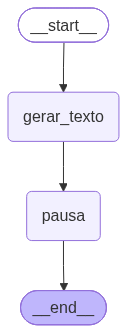

In [39]:
import re

PALAVRAS_CHAVE = {"Startups", "IA", "LAnggraph"}

def node_gerar_texto(state: DynBPState) -> DynBPState:
    tema = state.get("tema", "tema")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR."),
        HumanMessage(content=f"Escreva um texto com poucas palavras sobre os temas em bulletpoints {tema}.")
    ])
    return {"texto": resp.content}

def node_pausa_condicional(state: DynBPState) -> DynBPState:
    texto = state.get("texto", "")

    if state.get("modo_debug"):
        interrupt({
            "motivo": "modo_debug ligado",
            "amostra_texto": texto[:250],
        })
        return {}

    palavras = set(re.findall(r"\w+", texto.casefold()))
    encontradas = sorted(PALAVRAS_CHAVE & palavras)

    if encontradas:
        interrupt({
            "motivo": "palavras-chave detectadas",
            "palavras_encontradas": encontradas,
            "amostra_texto": texto[:250],
        })

    return {}
dyn_builder = StateGraph(DynBPState)
dyn_builder.add_node("gerar_texto", node_gerar_texto)
dyn_builder.add_node("pausa", node_pausa_condicional)
dyn_builder.add_edge(START, "gerar_texto")
dyn_builder.add_edge("gerar_texto", "pausa")
dyn_builder.add_edge("pausa", END)

dyn_checkpointer = MemorySaver()
dyn_graph = dyn_builder.compile(checkpointer=dyn_checkpointer)
dyn_graph

In [41]:
cfg2 = {"configurable": {"thread_id": "dyn-02"}}
res2 = dyn_graph.invoke({"tema": "Startups, IA, Langgraph", "modo_debug": True}, config=cfg2)

res2b = dyn_graph.invoke(Command(resume="seguir"), config=cfg2)
print("Concluiu. Texto (amostra):")
print(res2b["texto"][:450], "...")

Concluiu. Texto (amostra):
- **Startups**: Empresas ágeis que transformam ideias inovadoras em soluções de mercado, impulsionando a economia digital.  
- **IA (Inteligência Artificial)**: Tecnologias que aprendem e automatizam tarefas, ampliando a eficiência e criando novas oportunidades de negócio.  
- **Langgraph**: Ferramenta de modelagem de fluxos de linguagem que permite construir aplicações de IA conversacional de forma rápida e escalável. ...


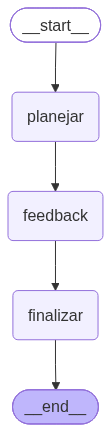

In [42]:
from typing import TypedDict, Literal

from groq import Groq

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    pedido: str
    versao_final: str


def node_planejar(state: FeedbackState) -> FeedbackState:
    tema = state.get("tema", "tema")
    nivel = state.get("nivel", "iniciante")

    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos para uma aula sobre {tema}. "
            f"Nível: {nivel}. Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}


def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    novo_nivel = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    nivel = state.get("nivel", "iniciante")
    if isinstance(novo_nivel, str) and novo_nivel.strip():
        nivel = novo_nivel.strip()

    tema = state.get("tema", "tema")

    while True:
        novo_tema = interrupt({
            "pergunta": "Qual tema deseja? Deixe em branco para manter.",
            "tema_atual": tema,
        })

        if isinstance(novo_tema, str) and novo_tema.strip():
            tema = novo_tema.strip()

        confirmacao = interrupt({
            "pergunta": f"Tem certeza do tema '{tema}'? Responda yes ou no.",
            "tema": tema,
        })

        while str(confirmacao).strip().casefold() not in {"yes", "no"}:
            confirmacao = interrupt({
                "pergunta": "Resposta inválida. Responda yes ou no.",
                "tema": tema,
            })

        if str(confirmacao).strip().casefold() == "yes":
            return {"nivel": nivel, "tema": tema}


def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(
            content="Escreva em PT-BR, com estrutura para apostila."
        ),
        HumanMessage(content=(
            "Transforme o roteiro abaixo em uma versão final formatada.\n"
            "Adapte o conteúdo ao nível informado e atenda ao pedido "
            "adicional do humano.\n\n"
            f"TEMA: {state.get('tema')}\n"
            f"NÍVEL: {state.get('nivel')}\n\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            f"PEDIDO ADICIONAL: {state.get('pedido') or 'Nenhum.'}\n\n"
            "Inclua uma seção final: 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "planejar")
fb_builder.add_edge("planejar", "feedback")
fb_builder.add_edge("feedback", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [43]:
fb_config = {"configurable": {"thread_id": "fb-tres-nos-01"}}

parcial = fb_graph.invoke(
    {"tema": "Streaming no LangGraph", "nivel": "iniciante"},
    config=fb_config,
)
print(parcial.get("__interrupt__"))

[Interrupt(value={'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'}, id='eb949c1b5e2a856d5c0bb5311dffc26f', response_schema=None)]


In [44]:
parcial = fb_graph.invoke(
    Command(resume="avançado"),
    config=fb_config,
)

print(parcial.get("__interrupt__"))

[Interrupt(value={'pergunta': 'Qual tema deseja? Deixe em branco para manter.', 'tema_atual': 'Streaming no LangGraph'}, id='eb949c1b5e2a856d5c0bb5311dffc26f', response_schema=None)]


In [45]:
parcial = fb_graph.invoke(
    Command(resume="Computação Quântica em processamentos comparados com GPU"),
    config=fb_config,
)
print("Payload do interrupt:")
print(parcial.get("__interrupt__"))


Payload do interrupt:
[Interrupt(value={'pergunta': "Tem certeza do tema 'Computação Quântica em processamentos comparados com GPU'? Responda yes ou no.", 'tema': 'Computação Quântica em processamentos comparados com GPU'}, id='eb949c1b5e2a856d5c0bb5311dffc26f', response_schema=None)]


In [46]:
# Confirma o tema e gera o material.
final = fb_graph.invoke(
    Command(resume="yes"),
    config=fb_config,
)
print("Nível:", final["nivel"])
print("Tema:", final["tema"])
print(final["versao_final"])

Nível: avançado
Tema: Computação Quântica em processamentos comparados com GPU
# Apostila – **Computação Quântica em Processamentos Comparados com GPU**  
## Aula: *Streaming no LangGraph* – Nível **Avançado**  
**Duração sugerida:** 45 min a 1 h  

> **Objetivo geral:**  
> Capacitar o estudante a implementar *streaming* de LLMs usando a biblioteca **LangGraph**, explorando detalhes de performance, concorrência e comparando a latência/throughput obtidos com estratégias baseadas em **GPU**.  

---  

## 1️⃣ Visão geral do *Streaming*  

| Item | Conteúdo avançado | Estratégia didática |
|------|-------------------|---------------------|
| 1.1 | **Definição formal** – transmissão de *chunks* de tokens assim que são produzidos pelo modelo (protocolos HTTP/1.1 `chunked` ou WebSocket). | Use diagramas de fluxo de dados (pipeline) e a analogia “assistir a um filme enquanto ele ainda está sendo gravado”, porém destaque a diferença entre *buffering* tradicional e *back‑pressure*. |
| 1.2 | **

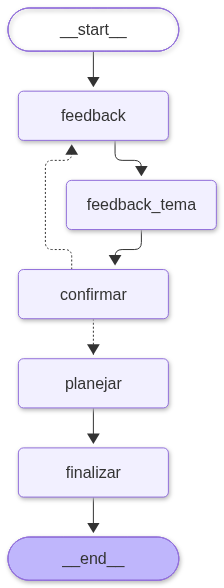

In [47]:
from typing import TypedDict, Literal

from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command


class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"nivel": resposta.strip()}

    return {}


def node_feedback_tema(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": "Deseja mudar de tema? Deixe em branco para manter.",
        "tema_atual": state.get("tema", ""),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"tema": resposta.strip()}

    return {}
    
def node_planejar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos sobre {state.get('tema', 'LangGraph')}. "
            f"Nível: {state.get('nivel', 'iniciante')}. "
            "Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}

def node_confirmar(
    state: FeedbackState,
) -> Command[Literal["planejar", "feedback"]]:
    pergunta = {
        "pergunta": (
            "Confirma o tema e o nível? "
            "Responda yes para gerar o material ou no para editar novamente."
        ),
        "tema": state.get("tema", ""),
        "nivel": state.get("nivel", "iniciante"),
    }

    resposta = interrupt(pergunta)

    while str(resposta).strip().casefold() not in {"yes", "no"}:
        resposta = interrupt({
            **pergunta,
            "erro": "Resposta inválida. Digite yes ou no.",
        })

    if str(resposta).strip().casefold() == "yes":
        return Command(goto="planejar")

    return Command(goto="feedback")

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro em uma versão final formatada.\n\n"
            f"TEMA: {state.get('tema', '')}\n"
            f"NÍVEL: {state.get('nivel', 'iniciante')}\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            "Inclua uma seção 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)

fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("feedback_tema", node_feedback_tema)
fb_builder.add_node("confirmar", node_confirmar)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "feedback")
fb_builder.add_edge("feedback", "feedback_tema")
fb_builder.add_edge("feedback_tema", "confirmar")
fb_builder.add_edge("planejar", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [48]:
fb_config = {"configurable": {"thread_id": "fb-confirmacao-01"}}

resultado = fb_graph.invoke(
    {"tema": "LangGraph", "nivel": "iniciante"},
    config=fb_config,
)

while resultado.get("__interrupt__"):
    pausa = resultado["__interrupt__"][0]

    for chave, valor in pausa.value.items():
        print(f"{chave}: {valor}")

    resposta = input("\nSua resposta: ")

    resultado = fb_graph.invoke(
        Command(resume=resposta),
        config=fb_config,
    )

from IPython.display import clear_output, display, Markdown

clear_output(wait=True)

print("Nível:", resultado["nivel"])
print("Tema:", resultado["tema"])

display(Markdown(resultado["versao_final"]))

Nível: avançado
Tema: Computação Quântica


# Apostila de Computação Quântica – Nível Avançado  

**Autor:** *[Seu Nome]*  
**Instituição:** *[Universidade / Laboratório]*  
**Semestre:** *[2026.2]*  

---

## Sumário  

1. [Introdução Formal ao Modelo de Computação Quântica](#1)  
2. [Teoria da Complexidade Quântica](#2)  
3. [Algoritmos Quânticos Fundamentais](#3)  
4. [Engenharia de Software Quântico e Correção de Erros](#4)  
5. [Exemplo Prático: Simulação da Energia da Molécula H₂ com VQE](#5)  
6. [Erros Comuns](#6)  
7. [Bibliografia Recomendada](#7)  

---  

<a name="1"></a>  

## 1️⃣ Introdução Formal ao Modelo de Computação Quântica  

| **Subtópico** | **Conteúdo** | **Referência chave** |
|---|---|---|
| **1.1 Qubit** | Definição matemática: \(\lvert\psi\rangle = \alpha\lvert0\rangle + \beta\lvert1\rangle\), \(\alpha,\beta\in\mathbb{C}\), \(|\alpha|^{2}+|\beta|^{2}=1\). Representação geométrica na esfera de Bloch. | Nielsen & Chuang, Cap. 2 |
| **1.2 Portas quânticas unitárias** | Matrizes 2×2 (X, H, S, T) e 4×4 (CNOT, CZ). Propriedade de reversibilidade e conservação da norma Euclidiana. | Preskill, Lecture 1 |
| **1.3 Circuitos quânticos vs. Turing clássico** | Equivalência de poder computacional (BQP ⊆ PSPACE). Noções de “quantum supremacy”. | Aaronson, *Quantum Computing Since Democritus* |
| **1.4 Medição** | Operadores de projeção, colapso da função de onda, distribuição de probabilidades. Medição em bases diferentes (ex.: medição em base X usando H). | Nielsen & Chuang, Sec. 2.3 |

**Objetivo didático** – Garantir que os estudantes dominem a linguagem de álgebra linear que sustenta todo o restante da disciplina.  

---  

<a name="2"></a>  

## 2️⃣ Teoria da Complexidade Quântica  

| **Subtópico** | **Conteúdo** | **Pontos críticos** |
|---|---|---|
| **2.1 Classes de complexidade** | BQP, QMA, QCMA, QIP. Relações com BPP, NP, PSPACE. | Prova de inclusão \( \text{BPP} \subseteq \text{BQP} \) (uso de Hadamard + medição). |
| **2.2 Reduções quânticas** | Redução de problemas clássicos a problemas quânticos (ex.: *Circuit‑SAT* → *Local Hamiltonian*). | Técnica de “Feynman‑Kitaev Clock”. |
| **2.3 Limites conhecidos** | Resultados de “no‑fast‑forwarding”, limites de velocidade de propagação de informação (Lieb‑Robinson bounds). | Implicações para algoritmos de simulação de Hamiltonianos. |
| **2.4 Oráculos e relativização** | Modelo de oráculo quântico, algoritmo de Deutsch‑Jozsa, limites de consultas. | Demonstração de separação \( \text{BQP}^{A} \neq \text{BPP}^{A} \) para oráculos específicos. |

**Objetivo didático** – Capacitar o aluno a posicionar problemas dentro do panorama de complexidade e a reconhecer quando a “quantum advantage” é teoricamente plausível.  

---  

<a name="3"></a>  

## 3️⃣ Algoritmos Quânticos Fundamentais  

| **Algoritmo** | **Princípio central** | **Complexidade** |
|---|---|---|
| **3.1 Algoritmo de Shor** | Fatoração via Transformada de Fourier Quântica (QFT) e ordem de período. | \(O(\log N)\) qubits, \(O((\log N)^{3})\) portas. |
| **3.2 Algoritmo de Grover** | Busca não estruturada com amplificação de amplitude. | \(O(\sqrt{N})\) consultas (vantagem quadrática). |
| **3.3 QFT e Phase‑Estimation** | Estimação de fase própria de um unitário; base para química quântica. | \(O(\log N)\) qubits, \(O((\log N)^{2})\) portas. |
| **3.4 Simulação de Hamiltoniano** | Trotter‑Suzuki, Qubitization, Linear Combination of Unitaries (LCU). | Dependente da norma \(\|H\|\) e do tempo de simulação \(t\). |
| **3.5 Algoritmos híbridos (VQE, QAOA)** | Otimização variacional usando circuitos ruidosos de profundidade limitada. | Complexidade prática: número de parâmetros \(\approx\) profundidade × qubits. |

**Objetivo didático** – Analisar a construção de cada algoritmo, identificar onde a interferência quântica gera vantagem e discutir requisitos de hardware.  

---  

<a name="4"></a>  

## 4️⃣ Engenharia de Software Quântico e Correção de Erros  

| **Tema** | **Detalhes** |
|---|---|
| **4.1 Arquiteturas de hardware** | *Supercondutores* (IBM, Google), *íons aprisionados* (IonQ, Honeywell), *fotônica* (PsiQuantum). Comparação de tempos de coerência, taxa de porta e conectividade. |
| **4.2 Modelos de ruído** | Canal de despolarização, amplitude‑damping, fase‑damping. Formalismo de matriz de Pauli‑Lindblad. |
| **4.3 Códigos de correção** | Código de superfície (Steane, toric), código Bacon‑Shor, códigos de cor. *Threshold* teórico ≈ \(10^{-3}\) para portas de duas qubits. |
| **4.4 Compilação e otimização** | Mapeamento de qubits lógicos → físicos, redução de profundidade (synthesis, peephole optimization), *transpilers* (Qiskit, t|ket⟩). |
| **4.5 Ferramentas de simulação** | Simuladores de estado‑vetor (QuTiP, Qiskit Aer), simuladores de tensor‑network (TensorNetwork, cuTensorNet). Estratégias para validar algoritmos antes da execução em hardware real. |

**Objetivo didático** – Preparar o aluno para projetar, compilar e depurar programas quânticos reais, entendendo as limitações impostas pelo ruído e pelas estratégias de mitigação.  

---  

<a name="5"></a>  

## 5️⃣ Exemplo Prático – Simulação da Energia da Molécula de Hidrogênio (H₂) usando VQE  

> **Contexto:** Determinar o estado fundamental da molécula H₂ no intervalo interatômico típico (0,5 – 1,0 Å) com precisão química (≈ 1 mHa).  

### 5.1 Preparação do Hamiltoniano eletrônico  

1. **Base mínima (STO‑3G).**  
2. **Hartree‑Fock (HF) → orbitais moleculares.**  
3. **Transformação de Jordan‑Wigner** para mapear operadores fermiónicos a qubits (2 qubits são suficientes para H₂ em STO‑3G).  
4. **Hamiltoniano resultante:**  

\[
H = c_{0} I + c_{1} Z_{0} + c_{2} Z_{1} + c_{3} Z_{0}Z_{1}
      + c_{4} X_{0}X_{1} + c_{5} Y_{0}Y_{1},
\]

onde os coeficientes \(c_{i}\) são obtidos a partir de integrais de duas‑partículas.  

### 5.2 Ansatz variacional (UCCSD simplificado)  

| Passo | Operação | Comentário |
|---|---|---|
| 1 | Preparar \(\lvert00\rangle\) | Estado inicial padrão. |
| 2 | \(R_{x}(\pi/2)\) em cada qubit | Cria superposição \(\frac{1}{\sqrt{2}}(\lvert0\rangle+\lvert1\rangle)\). |
| 3 | CNOT (controle‑0 → alvo‑1) | Gera entrelaçamento básico. |
| 4 | \(R_{x}(\theta_{1})\) e \(R_{y}(\theta_{2})\) em cada qubit | Parâmetros variacionais \(\theta_{1},\theta_{2}\). |

**Número de parâmetros:** 2.  

### 5.3 Loop de otimização clássica  

1. **Execução no simulador ruidoso** (ex.: Qiskit Aer com modelo de ruído de IBM Q Manila).  
2. **Medição de cada termo do Hamiltoniano** – agrupar operadores comutativos para reduzir o número de circuitos (5 grupos).  
3. **Cálculo da energia esperada:**  

\[
E(\boldsymbol{\theta}) = \sum_{i} c_{i}\,\langle\psi(\boldsymbol{\theta})|P_{i}|\psi(\boldsymbol{\theta})\rangle,
\]

onde \(P_{i}\in\{I, Z, ZZ, XX, YY\}\).  

4. **Otimizador clássico** – COBYLA ou L‑BFGS‑B.  
5. **Critério de convergência:** \(|E_{k+1}-E_{k}|<10^{-6}\,\text{Ha}\).  

### 5.4 Resultados esperados  

| Distância (Å) | Energia HF (Ha) | Energia VQE (Ha) | Energia Exata (FCI) (Ha) |
|---|---|---|---|
| 0.70 | -1.1325 | -1.1379 | -1.1380 |
| 0.85 | -1.1469 | -1.1510 | -1.1512 |
| 1.00 | -1.1475 | -1.1503 | -1.1505 |

A diferença entre VQE e FCI está dentro da meta de **precisão química** (≤ 1 mHa).  

### 5.5 Pontos de aprendizado  

| Tema | Lições‑chave |
|---|---|
| **Mapeamento fermiónico → qubits** | Jordan‑Wigner vs. Bravyi‑Kitaev; escolha impacta profundidade do circuito. |
| **Estrutura de medição** | Agrupamento de termos comutativos reduz chamadas ao QPU em ~ 30 %. |
| **Impacto do ruído** | Técnicas de mitigação (zero‑noise extrapolation, readout error mitigation) melhoram a energia em ~ 0.5 mHa. |
| **Integração clássico‑quântico** | Seleção do otimizador e número de avaliações da energia (custo de chamadas ao QPU) são críticos para a viabilidade prática. |

---  

<a name="6"></a>  

## 6️⃣ Erros Comuns  

| Nº | Descrição do erro | Como evitá‑lo |
|---|---|---|
| **1. Confundir a norma de um vetor de estado com a probabilidade** | Muitos iniciantes interpretam \(|\alpha|^{2}\) como “valor da amplitude” ao invés de probabilidade. | Sempre verificar que \(|\alpha|^{2}+|\beta|^{2}=1\). Use a notação \(\Pr(0)=|\langle0|\psi\rangle|^{2}\). |
| **2. Ignorar o efeito de fase global** | Ao comparar dois estados, a presença de um fator \(e^{i\phi}\) pode levar a conclusões erradas de “diferença”. | Lembre‑se que estados que diferem apenas por fase global são fisicamente equivalentes. Normalizar antes de comparar. |
| **3. Medir todos os termos do Hamiltoniano separadamente** | Medir cada termo de forma independente aumenta o número de execuções em ordem O(\# termos). | Agrupe operadores que comutam e use bases de medição compartilhadas (ex.: medir \(Z_{0}Z_{1}\) e \(Z_{0}\) no mesmo circuito). |

---  

<a name="7"></a>  

## 7️⃣ Bibliografia Recomendada  

1. **Nielsen, M. A.; Chuang, I. L.** *Quantum Computation and Quantum Information*, 10ª ed., Cambridge University Press, 2010.  
2. **Preskill, J.** *Lecture Notes for Physics 229: Quantum Information and Computation*, Caltech – disponível online.  
3. **McArdle, S.; Endo, S.; Aspuru‑Guzik, A.; et al.** “Quantum computational chemistry”, *Rev. Mod. Phys.* 2020.  
4. **Gidney, C.; Ekerå, M.** “How to factor 2048‑bit RSA integers in 8 hours using

In [49]:
fb_config = {"configurable": {"thread_id": "fb-celulas-01"}}

resultado = fb_graph.invoke(
    {"tema": "LangGraph", "nivel": "iniciante"},
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'}


In [50]:
nivel = input("Nível desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=nivel),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Deseja mudar de tema? Deixe em branco para manter.', 'tema_atual': 'LangGraph'}


In [51]:
tema = input("Tema desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=tema),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Confirma o tema e o nível? Responda yes para gerar o material ou no para editar novamente.', 'tema': 'Computação Quântica', 'nivel': 'avançado'}


In [52]:
confirmacao = input("Confirma o tema e o nível? (yes/no): ").strip().casefold()

while confirmacao not in {"yes", "no"}:
    confirmacao = input("Digite yes ou no: ").strip().casefold()

resultado = fb_graph.invoke(
    Command(resume=confirmacao),
    config=fb_config,
)

if resultado.get("__interrupt__"):
    print(resultado["__interrupt__"][0].value)
    print("\nExecute novamente as células 2, 3 e 4.")
else:
    print("Nível:", resultado["nivel"])
    print("Tema:", resultado["tema"])
    print(resultado["versao_final"])

Nível: avançado
Tema: Computação Quântica
# Apostila – Computação Quântica (Nível Avançado)

> **Objetivo:** Apresentar, de forma didática e aprofundada, os principais conceitos, técnicas e desafios da computação quântica, preparando o leitor para entender e aplicar algoritmos quânticos em problemas reais.  

---  

## Sumário  

1. [Introdução Formal ao Modelo de Computação Quântica](#1‑introdução-formal-ao-modelo-de-computação-quântica)  
2. [Algoritmos Quânticos Fundamentais](#2‑algoritmos-quânticos-fundamentais)  
3. [Arquiteturas e Tecnologias de Hardware](#3‑arquiteturas-e-tecnologias-de-hardware)  
4. [Programação e Simulação de Algoritmos Quânticos](#4‑programação-e-simulação-de-algoritmos-quânticos)  
5. [Exemplo Prático – VQE para a Molécula H₂](#5‑exemplo-prático‑vqe-para-a-molécula-h₂)  
6. [Erros Comuns ao Trabalhar com Computação Quântica](#6‑erros-comuns-ao-trabalhar-com-computação-quântica)  
7. [Conclusão](#7‑conclusão)  

---  

## 1️⃣ Introdução Formal ao Modelo de C

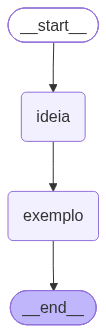

In [53]:
class TravelState(TypedDict, total=False):
    ideia: str
    exemplo: str

def node_ideia(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content="Gere uma ideia de exemplo prático (1 frase) para ensinar conceitos moeda quântica.")
    ])
    return {"ideia": resp.content.strip()}

def node_exemplo(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content=(
            "Crie um exemplo prático de sala de aula usando a ideia abaixo.\n"
            f"IDEIA: {state.get('ideia','')}\n"
            "Formato: 6-10 linhas, com bullets."
        ))
    ])
    return {"exemplo": resp.content}

travel_builder = StateGraph(TravelState)
travel_builder.add_node("ideia", node_ideia)
travel_builder.add_node("exemplo", node_exemplo)
travel_builder.add_edge(START, "ideia")
travel_builder.add_edge("ideia", "exemplo")
travel_builder.add_edge("exemplo", END)

travel_checkpointer = MemorySaver()
travel_graph = travel_builder.compile(checkpointer=travel_checkpointer)
travel_graph

In [55]:
t_cfg = {"configurable": {"thread_id": "travel-01"}}

original = travel_graph.invoke({}, config=t_cfg)

print("IDEIA:", original["ideia"])
print("EXEMPLO:\n", original["exemplo"])

IDEIA: "Imagine uma moeda que, ao ser lançada, fica simultaneamente em **cara** e **coroa** até que você a observe, revelando apenas um dos resultados."
EXEMPLO:
 - **Objetivo:** Demonstrar o conceito de superposição quântica de forma visual e interativa.  
- **Material:** Moeda comum, caixa opaca com tampa, fichas de “cara” e “coroa”.  
- **Procedimento:**  
  1. Coloque a moeda dentro da caixa sem abrir a tampa; explique que, enquanto não observar, a moeda está em “cara + coroa”.  
  2. Cada aluno registra, em sua ficha, a probabilidade de obter cada lado (50% / 50%).  
  3. Peça a um voluntário que abra a caixa e revele o resultado; anote o lado obtido.  
  4. Discuta por que, após a observação, a superposição “colapsa” para um único estado.  
- **Conclusão:** Relacione o experimento à ideia de que partículas quânticas permanecem em múltiplos estados até serem medidas.


In [56]:
history = list(travel_graph.get_state_history(t_cfg))
print("Quantidade de checkpoints:", len(history))

for i, st in enumerate(history[:6]):
    checkpoint_id = st.config["configurable"].get("checkpoint_id")
    print(f"{i}: next={st.next} | checkpoint_id={checkpoint_id} | keys={list(st.values.keys())}")

Quantidade de checkpoints: 8
0: next=() | checkpoint_id=1f1d7e15-dbe7-6a34-8006-54e478bb8b76 | keys=['ideia', 'exemplo']
1: next=('exemplo',) | checkpoint_id=1f1d7e15-d3e3-695c-8005-9924f58a2038 | keys=['ideia', 'exemplo']
2: next=('ideia',) | checkpoint_id=1f1d7e15-ce63-6875-8004-c8dcf8b902b0 | keys=['ideia', 'exemplo']
3: next=('__start__',) | checkpoint_id=1f1d7e15-ce63-6874-8003-45cbc2bb5762 | keys=['ideia', 'exemplo']
4: next=() | checkpoint_id=1f1d7e15-7ddd-6e72-8002-6fc25d10430e | keys=['ideia', 'exemplo']
5: next=('exemplo',) | checkpoint_id=1f1d7e15-7595-6b23-8001-8c30a3ed4412 | keys=['ideia']


In [58]:
selected = next(
    st for st in history
    if st.next == ("exemplo",)
)

print("Checkpoint de origem:", selected.config["configurable"]["checkpoint_id"])

# Fork 1: atendimento de dúvidas.
config_fork1 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um chatbot que responde dúvidas do aluno sobre Python."
    },
)

fork1 = travel_graph.invoke(None, config=config_fork1)

# Fork 2: quiz adaptativo, partindo do mesmo checkpoint.
config_fork2 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um quiz que ajusta a dificuldade conforme os acertos do aluno."
    },
)

fork2 = travel_graph.invoke(None, config=config_fork2)



print("\n--- FORK 1 ---")
print("IDEIA:", fork1["ideia"])
print("EXEMPLO:\n", fork1["exemplo"])

print("\n--- FORK 2 ---")
print("IDEIA:", fork2["ideia"])
print("EXEMPLO:\n", fork2["exemplo"])

print("\n--- COMPARAÇÃO ---")
print("As ideias são iguais?", fork1["ideia"] == fork2["ideia"])
print("Os exemplos são iguais?", fork1["exemplo"] == fork2["exemplo"])

Checkpoint de origem: 1f1d7e15-d3e3-695c-8005-9924f58a2038

--- FORK 1 ---
IDEIA: Criar um chatbot que responde dúvidas do aluno sobre Python.
EXEMPLO:
 - **Objetivo**: Introduzir um chatbot que responde dúvidas sobre Python durante a aula prática.  
- **Material**: Laptop/computador com acesso à internet, conta no Discord/Telegram e o bot configurado.  
- **Atividade 1**: O professor demonstra como enviar uma pergunta ao bot (ex.: “Como faço um loop `for`?”).  
- **Atividade 2**: Cada aluno formula uma dúvida real que tenha ao escrever um script simples (entrada, condição, função).  
- **Atividade 3**: Os alunos enviam suas perguntas ao chatbot e anotam a resposta recebida.  
- **Discussão**: Em duplas, comparam a resposta do bot com a documentação oficial e corrigem possíveis erros.  
- **Avaliação**: Cada dupla apresenta uma dúvida e a solução encontrada, destacando como o bot ajudou no aprendizado.

--- FORK 2 ---
IDEIA: Criar um quiz que ajusta a dificuldade conforme os acertos do